# 057 — xgboost afinacao

XGBoost 007: mantém 200 árvores, profundidade 5 e learning rate 0,1. Testa min_child_weight, subsample e colsample_bytree.

**Estado: executado pelo runner; resultados locais guardados.** A seleção usa três folds dentro de 8.769 linhas. A validação fixa de 2.193 linhas é desenvolvimento, não teste independente. Nenhum modelo usa AGE_RANGE ou identificadores nas entradas.

057 resultado completo reutilizado após verificar contexto.
Protocolo: 3 folds dentro de 8769 linhas; 2193 apenas para desenvolvimento. Sem early stopping: número de árvores histórico fixo.
Selecionado: {'label': 'combinado', 'kind': 'xgb', 'params': {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}, 'weighting': 'none'}
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração da corrida original (s), incluindo preparação e avaliação: 191.14524895799696
Diferenças emparelhadas CV: {'differences': [0.009210247977479713, 0.005493034614794279, -0.0024856658862413283], 'mean': 0.0040725389020108875, 'std': 0.005975948153173897}
Por escalão: controlo
Por escalão: selecionado
CSV: {'path': 'submissions/submission_057_xgboost_afinacao.csv', 'duplicate_of': [], 'differences': {'submission_001_regressao_logistica.csv': 

,configuração,Macro F1 CV,DP,folds
0,controlo_007,0.444887,0.005233,"[0.4471604261318295, 0.43890112932254693, 0.44..."
1,min_child_5,0.442963,0.004409,"[0.44775015417679714, 0.4420704384706172, 0.43..."
2,min_child_10,0.441108,0.005789,"[0.4402229386541722, 0.4358131680256516, 0.447..."
3,subsample_08,0.442417,0.004789,"[0.44017447980802893, 0.43916140062412357, 0.4..."
4,colsample_08,0.442092,0.010401,"[0.43985645328691947, 0.43299008021348806, 0.4..."
5,combinado,0.448959,0.006476,"[0.4563706741093092, 0.4443941639373412, 0.446..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.960540,0.952332
1,controlo,validation,0.449061,0.458276
2,selecionado,train,0.965741,0.959745
3,selecionado,validation,0.447430,0.457820


,classe,precision,recall,F1,support
0,0,0.777778,0.853659,0.813953,41
1,1,0.470588,0.235294,0.313725,34
2,2,0.571429,0.650000,0.608187,80
3,3,0.388889,0.280000,0.325581,75
4,4,0.338462,0.244444,0.283871,90
5,5,0.296552,0.333333,0.313869,129
6,6,0.352941,0.383721,0.367688,172
7,7,0.379310,0.381503,0.380403,173
8,8,0.593909,0.646409,0.619048,181
9,9,0.603774,0.630542,0.616867,203


,classe,precision,recall,F1,support
0,0,0.822222,0.902439,0.860465,41
1,1,0.352941,0.176471,0.235294,34
2,2,0.586207,0.637500,0.610778,80
3,3,0.373134,0.333333,0.352113,75
4,4,0.310811,0.255556,0.280488,90
5,5,0.306122,0.348837,0.326087,129
6,6,0.350649,0.313953,0.331288,172
7,7,0.378378,0.404624,0.391061,173
8,8,0.582915,0.640884,0.610526,181
9,9,0.638095,0.660099,0.648910,203


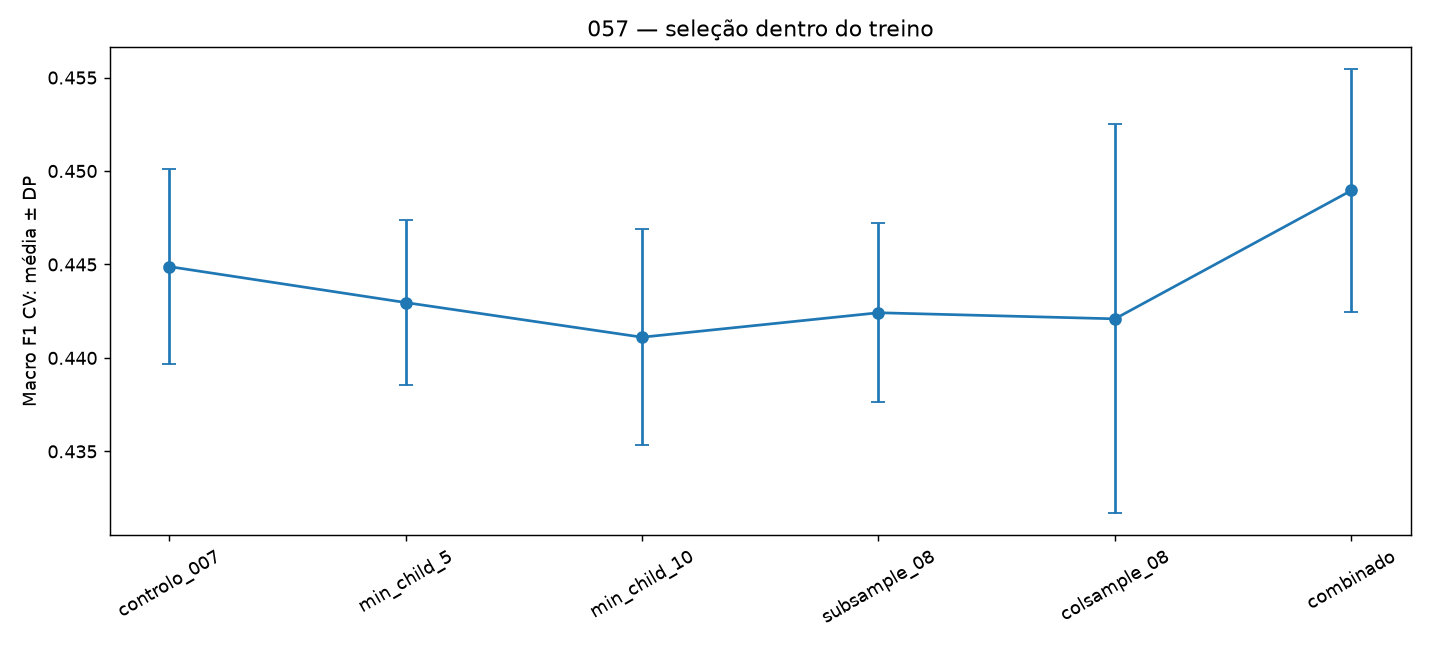

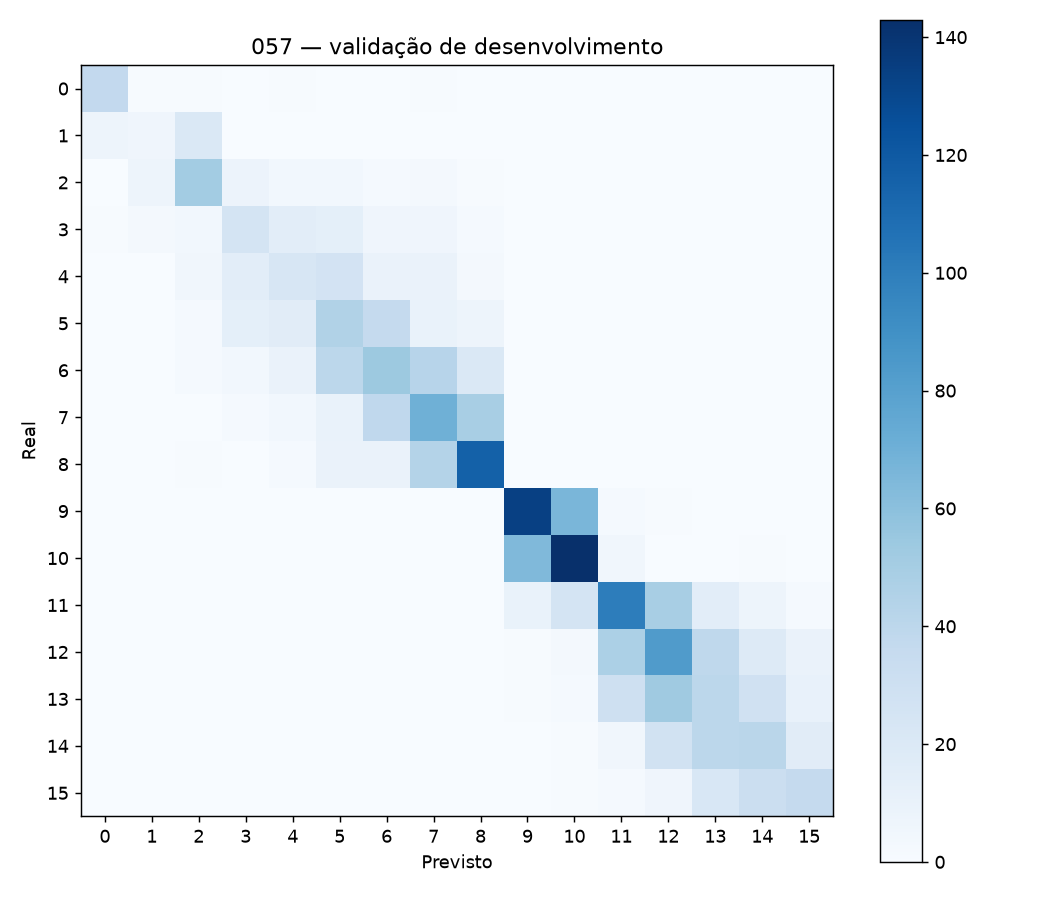

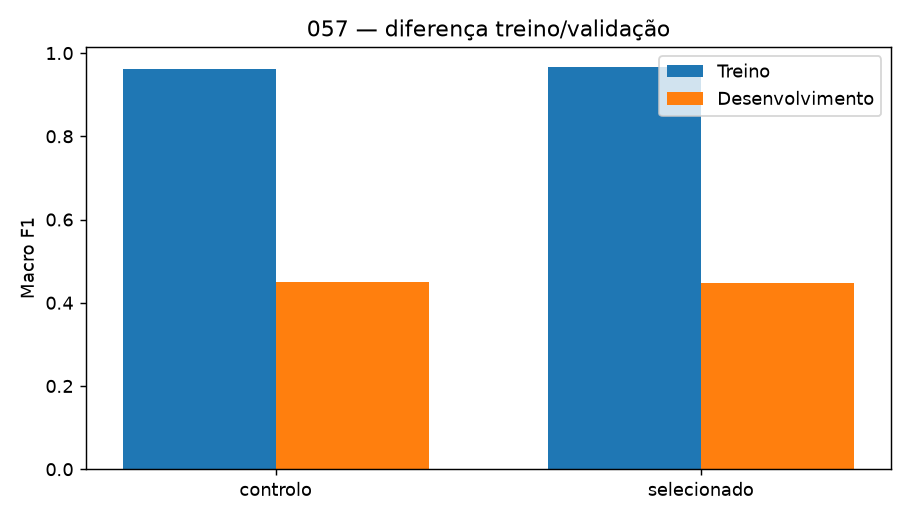

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/experiments_056_058.py').exists())
sys.path.insert(0, str(root))
from src.experiments_056_058 import run_experiment
result = run_experiment('057')
print('Protocolo:', result['protocol'])
print('Selecionado:', result['selected']['candidate'])
print('Versões:', result['context']['versions'])
print('Duração da corrida original (s), incluindo preparação e avaliação:', result['seconds'])
print('Diferenças emparelhadas CV:', result['paired_cv'])
display(pd.DataFrame([{'configuração':r['candidate']['label'], 'Macro F1 CV':r['mean'], 'DP':r['std'], 'folds':r['folds']} for r in result['candidates']]))
display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':m['macro_f1'],'accuracy':m['accuracy']} for name,groups in result['fixed'].items() for part,m in groups.items()]))
for name, groups in result['fixed'].items():
    print('Por escalão:', name)
    display(pd.DataFrame(groups['validation']['per_class']))
for p in sorted((root/'reports').glob('experiencia_057_*.png')):
    display(Image(filename=str(p)))
print('CSV:', result['submission'])
print('Kaggle:', result['kaggle_score'])


## Conclusões locais

- Macro F1: **0.4474**; accuracy: **0.4578**.
- Diferença face ao controlo contemporâneo: **-0.0016** no desenvolvimento.
- Seleção CV: `combinado`; diferença média emparelhada **+0.0041**.
- CSV: `submissions/submission_057_xgboost_afinacao.csv`. Motivo se não gerado: [].
- A seleção foi interna. Uma margem pequena ou um CSV distinto não prova melhoria no Kaggle.
- Melhorias seguintes: analisar estabilidade nos folds e os escalões 1, 6 e 13 antes de aumentar a pesquisa.

## Registo Kaggle
- Data: 19/11
- Pontuação Kaggle: 0.45
- Melhorias: testar árvores menos profundas e regularização L1/L2, numa pesquisa curta. Baixa prioridade agora; guardar esta configuração como componente de ensemble.